In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
import torch
import torch.nn as nn

SEED = 67
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)
rng = np.random.default_rng(SEED)
MODEL_DIR = "../models"
ART_DIR = "../artifacts"
RESULT_DIR = "../results"
PLOT_DIR = "../results/plots"
os.makedirs(PLOT_DIR, exist_ok=True)

with np.load(os.path.join(ART_DIR, "clean_data.npz"), allow_pickle=False) as data:
    X_train, X_test, y_test = data["X_train"], data["X_test"], data["y_test"]
    feature_names = data["feature_names"].tolist()
with np.load(os.path.join(ART_DIR, "poisoned_data.npz"), allow_pickle=False) as data:
    X_trigger = data["X_test_attacks_poisoned"]
    attack_indices = data["test_attack_indices"]
    trigger_features = data["trigger_feature_indices"]
with np.load(os.path.join(ART_DIR, "defense_results.npz"), allow_pickle=False) as data:
    assert np.array_equal(attack_indices, data["test_attack_indices"])
    feature_flags = data["feature_trigger_flags"]
    feature_scores = data["feature_trigger_scores"]
    before_predictions = data["dnn_test_predictions"][attack_indices]
    after_predictions = data["dnn_trigger_predictions"]
assert np.array_equal(attack_indices, np.flatnonzero(y_test == 1))
detector_bundle = joblib.load(os.path.join(MODEL_DIR, "backdoor_detectors.joblib"))
feature_threshold = detector_bundle["detectors"]["features"]["threshold"]
background_indices = rng.choice(len(X_train), size=30, replace=False)
background = X_train[background_indices]
clean_rf = joblib.load(os.path.join(MODEL_DIR, "clean", "clean_rf_model.joblib"))
poisoned_rf = joblib.load(os.path.join(MODEL_DIR, "poisoned", "poisoned_rf_model.joblib"))
normal_class = int(np.flatnonzero(clean_rf.classes_ == 0)[0])
assert np.array_equal(clean_rf.classes_, poisoned_rf.classes_)

In [2]:
# DNN ARCHITECTURE 
__torch_device = None
def get_torch_device():
    global __torch_device
    if __torch_device is not None:
        return __torch_device
    if  torch.backends.mps.is_available():
        print('Using MPS device for hardware acceleration')
        __torch_device = 'mps'
    elif torch.cuda.is_available():
        print('Using CUDA device for hardware acceleration')
        __torch_device = 'cuda'
    else:
        print('Hardware acceleration not available, using CPU')
        __torch_device = 'cpu'
    return __torch_device

device = get_torch_device()

class DNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),   
            nn.ReLU(),                   
            nn.BatchNorm1d(128),         
            nn.Dropout(0.2),             
            nn.Linear(128, 64),          
            nn.ReLU(),                   
            nn.BatchNorm1d(64),         
            nn.Dropout(0.2),            
            nn.Linear(64, 1)             
        )

    def forward(self, x, return_activations=False):
        acts = self.net[:8](x)           # input to the final Linear layer (64D penultimate representation)
        logits = self.net[8](acts)
        if return_activations:
            return logits, acts
        return logits



clean_dnn = DNN(X_test.shape[1]).to(device)
clean_dnn.load_state_dict(torch.load(os.path.join(MODEL_DIR, "clean", "clean_dnn_model.pth"),
                                     map_location=device, weights_only=True))
poisoned_dnn = DNN(X_test.shape[1]).to(device)
poisoned_dnn.load_state_dict(torch.load(os.path.join(MODEL_DIR, "poisoned", "poisoned_dnn_model.pth"),
                                        map_location=device, weights_only=True))
clean_dnn.eval()
poisoned_dnn.eval()

def normal_probability(model, X):
    model.eval()
    probabilities = []
    with torch.no_grad():
        for start in range(0, len(X), 2048):
            batch = torch.tensor(np.asarray(X[start:start+2048]), dtype=torch.float32).to(device)
            probabilities.append((1 - torch.sigmoid(model(batch))).cpu().numpy().reshape(-1))
    return np.concatenate(probabilities)

def rf_normal_shap(explainer, X):
    values = explainer.shap_values(X)
    return values[normal_class] if isinstance(values, list) else values[:, :, normal_class]

# for sklearn RandomForestClassifier the raw tree output is class probability
rf_explainers = {
    "RF clean": shap.TreeExplainer(clean_rf, feature_perturbation="tree_path_dependent", model_output="raw"),
    "RF poisoned": shap.TreeExplainer(poisoned_rf, feature_perturbation="tree_path_dependent", model_output="raw"),
}

Using MPS device for hardware acceleration


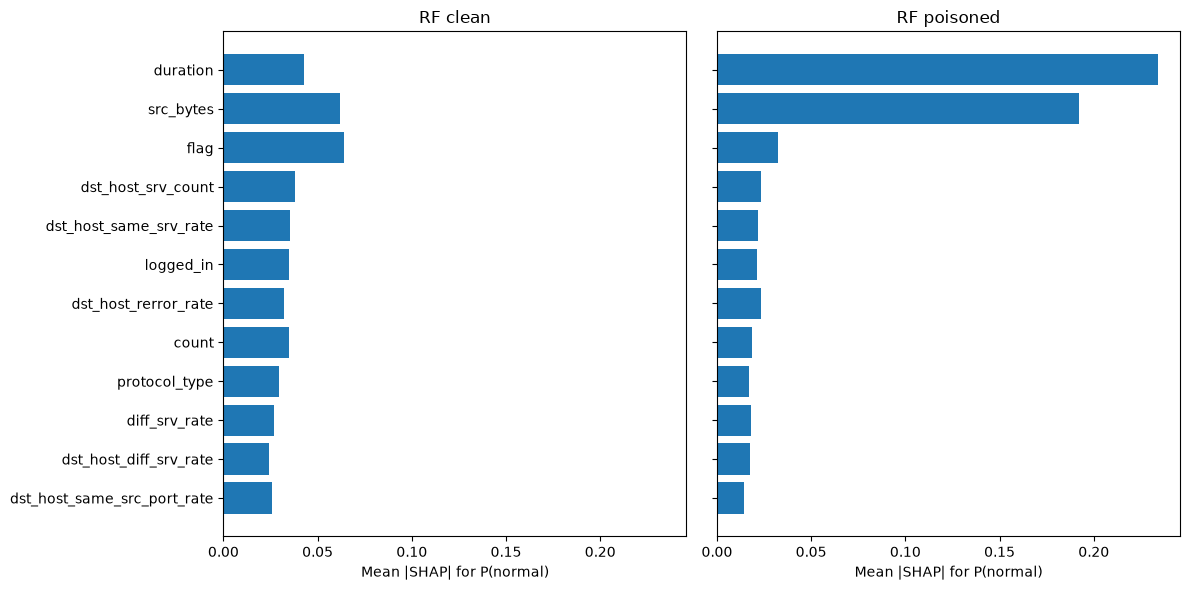

Trigger feature importance:
           RF clean  RF poisoned
duration   0.042710     0.234057
src_bytes  0.061873     0.191906


In [3]:
summary_indices = rng.choice(len(X_trigger), size=min(100, len(X_trigger)), replace=False)
summary_samples = X_trigger[summary_indices]
rf_summary_values = {name: rf_normal_shap(explainer, summary_samples)
                     for name, explainer in rf_explainers.items()}
importance = pd.DataFrame({name: np.abs(values).mean(axis=0)
                           for name, values in rf_summary_values.items()}, index=feature_names)
top_features = importance.mean(axis=1).nlargest(12).index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
for axis, name in zip(axes, rf_explainers):
    axis.barh(top_features, importance.loc[top_features, name])
    axis.set_title(name)
    axis.set_xlabel("Mean |SHAP| for P(normal)")
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "shap_rf_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Trigger feature importance:")
print(importance.loc[[feature_names[i] for i in trigger_features]].to_string())

In [4]:
eligible = (before_predictions == 1) & (after_predictions == 0)
selected, groups = [], []
for group, mask in [("detected", eligible & feature_flags), ("missed", eligible & ~feature_flags)]:
    candidates = np.flatnonzero(mask)
    count = min(2, len(candidates))
    chosen = rng.choice(candidates, size=count, replace=False)
    selected.extend(chosen.tolist())
    groups.extend([group] * count)
    print(f"{group}: {len(candidates)} available, {count} selected")
if not selected:
    raise ValueError("No suitable cases: check the attack and defense results.")
selected = np.array(selected, dtype=int)
original_samples = X_test[attack_indices[selected]]
trigger_samples = X_trigger[selected]
paired_samples = np.vstack([original_samples, trigger_samples])
case_count = len(selected)

values, base_values, probabilities = {}, {}, {}
for name, rf in [("RF clean", clean_rf), ("RF poisoned", poisoned_rf)]:
    values[name] = rf_normal_shap(rf_explainers[name], paired_samples)
    base_values[name] = float(rf_explainers[name].expected_value[normal_class])
    probabilities[name] = rf.predict_proba(paired_samples)[:, normal_class]
for name, dnn in [("DNN clean", clean_dnn), ("DNN poisoned", poisoned_dnn)]:
    print(f"KernelSHAP: {name}", flush=True)
    np.random.seed(SEED)
    explainer = shap.KernelExplainer(lambda X, current_model=dnn: normal_probability(current_model, X), background, link="identity")
    values[name] = np.asarray(explainer.shap_values(paired_samples, nsamples=512, l1_reg=0.0))
    base_values[name] = float(explainer.expected_value)
    probabilities[name] = normal_probability(dnn, paired_samples)
for name in values:
    error = np.max(np.abs(base_values[name] + values[name].sum(axis=1) - probabilities[name]))
    print(f"{name}: maximum reconstruction error = {error:.6f}")
    assert error < 0.001, "SHAP does not reconstruct the output: check the class and array shapes."

rows = []
for name in values:
    for i, (position, group) in enumerate(zip(selected, groups)):
        rows.append({"model": name, "test_index": int(attack_indices[position]), "group": group,
                     "p_normal_before": probabilities[name][i],
                     "p_normal_after": probabilities[name][i + case_count],
                     "trigger_shap_before": values[name][i, trigger_features].sum(),
                     "trigger_shap_after": values[name][i + case_count, trigger_features].sum(),
                     "detector_score_after": feature_scores[position],
                     "detector_threshold": feature_threshold})
case_results = pd.DataFrame(rows)
print(case_results.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

detected: 8108 available, 2 selected
missed: 194 available, 2 selected
KernelSHAP: DNN clean


100%|██████████| 8/8 [00:00<00:00, 47.76it/s]

KernelSHAP: DNN poisoned



100%|██████████| 8/8 [00:00<00:00, 81.75it/s]

RF clean: maximum reconstruction error = 0.000000
RF poisoned: maximum reconstruction error = 0.000000
DNN clean: maximum reconstruction error = 0.000000
DNN poisoned: maximum reconstruction error = 0.000000
       model  test_index    group  p_normal_before  p_normal_after  trigger_shap_before  trigger_shap_after  detector_score_after  detector_threshold
    RF clean       12271 detected           0.6900          0.6400               0.0017             -0.0754                0.6342              0.5289
    RF clean        2341 detected           0.0000          0.1700               0.0012              0.0724                0.6827              0.5289
    RF clean       13015   missed           0.1700          0.2700              -0.1685             -0.1507                0.4903              0.5289
    RF clean       20956   missed           0.2043          0.3489              -0.0139             -0.0205                0.5266              0.5289
 RF poisoned       12271 detected         

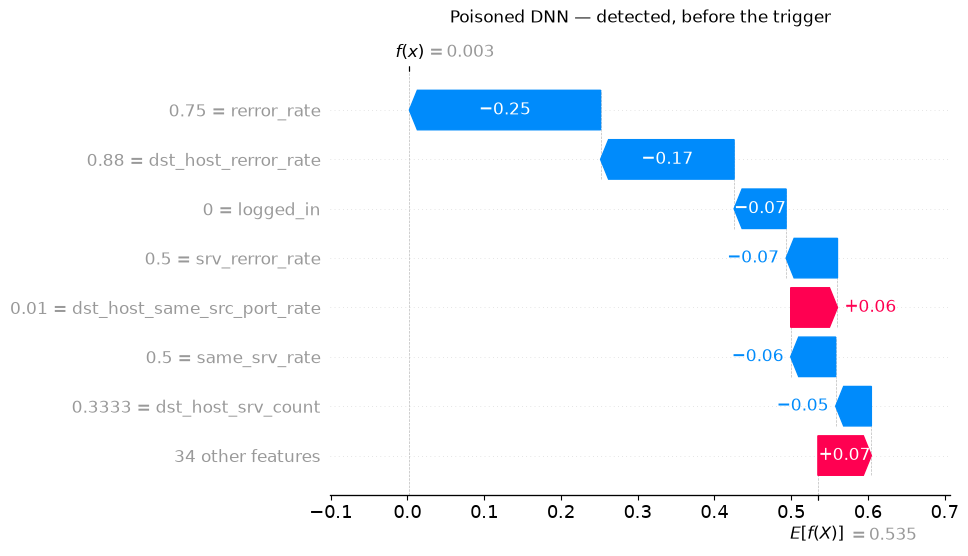

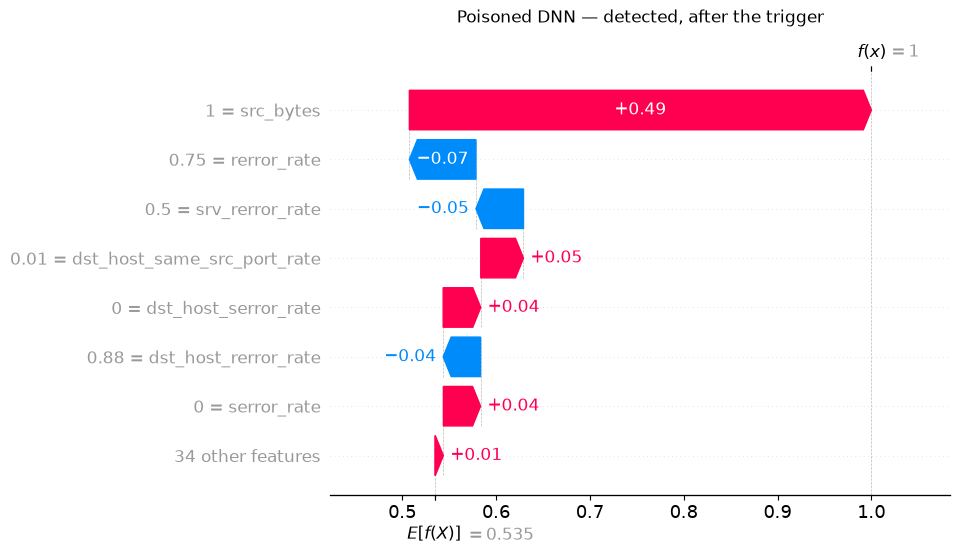

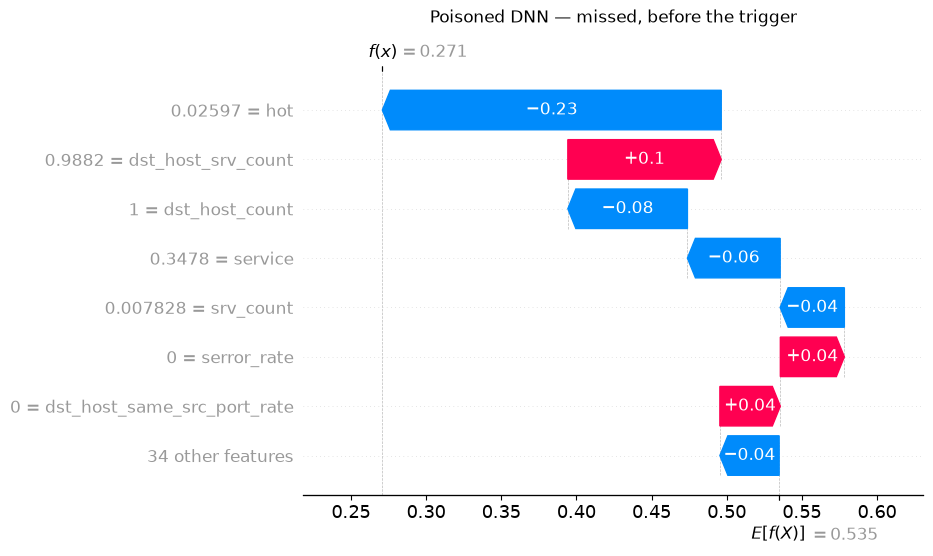

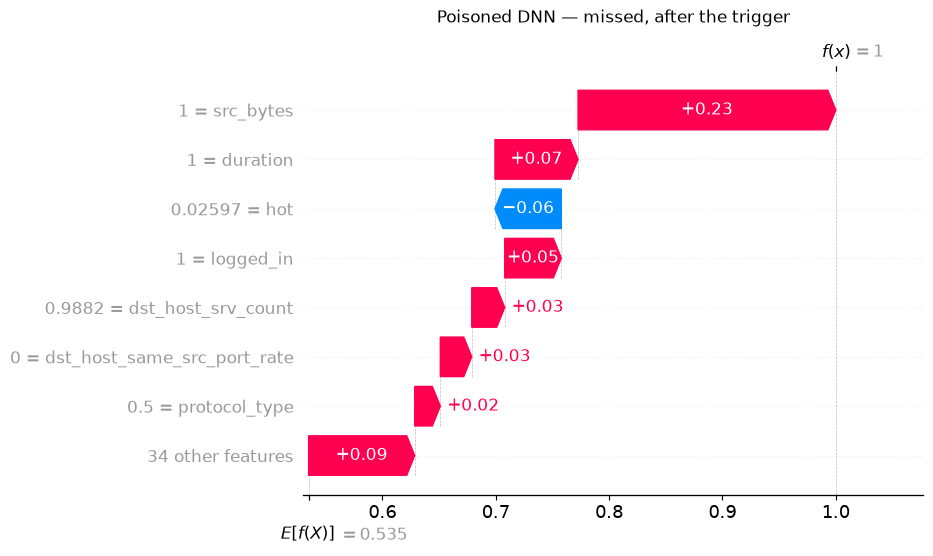

In [5]:
for group in dict.fromkeys(groups):
    i = groups.index(group)
    for offset, state in [(0, "before"), (case_count, "after")]:
        row = i + offset
        explanation = shap.Explanation(values=values["DNN poisoned"][row],
                                       base_values=base_values["DNN poisoned"],
                                       data=paired_samples[row], feature_names=feature_names)
        plt.figure()
        shap.plots.waterfall(explanation, max_display=8, show=False)
        order = np.argsort(-np.abs(explanation.values))[:7]
        labels = [f"{explanation.data[j]:.4g} = {feature_names[j]}" for j in order]
        axis = plt.gcf().axes[0]
        axis.set_yticks(range(8))
        axis.set_yticklabels(["34 other features"] + labels[::-1], fontsize=12)
        plt.gca().set_title(f"Poisoned DNN — {group}, {state} the trigger", pad=35)
        plt.savefig(os.path.join(PLOT_DIR, f"shap_dnn_{group}_{state}.png"), dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()

In [6]:
importance.to_csv(os.path.join(RESULT_DIR, "shap_rf_importance.csv"), index_label="feature")
case_results.to_csv(os.path.join(RESULT_DIR, "shap_case_comparison.csv"), index=False)
np.savez(
    os.path.join(ART_DIR, "shap_results.npz"),
    background_train_indices=background_indices, summary_attack_positions=summary_indices,
    selected_attack_positions=selected, selected_test_indices=attack_indices[selected],
    selected_groups=np.asarray(groups), feature_names=np.asarray(feature_names),
    paired_samples=paired_samples,
    rf_clean_values=values["RF clean"], rf_poisoned_values=values["RF poisoned"],
    dnn_clean_values=values["DNN clean"], dnn_poisoned_values=values["DNN poisoned"],
    model_names=np.asarray(list(values)), base_values=np.asarray([base_values[name] for name in values]),
    probabilities=np.stack([probabilities[name] for name in values]),
)
print("Plots, case comparison, and SHAP values saved. Models and detectors unchanged.")

Plots, case comparison, and SHAP values saved. Models and detectors unchanged.


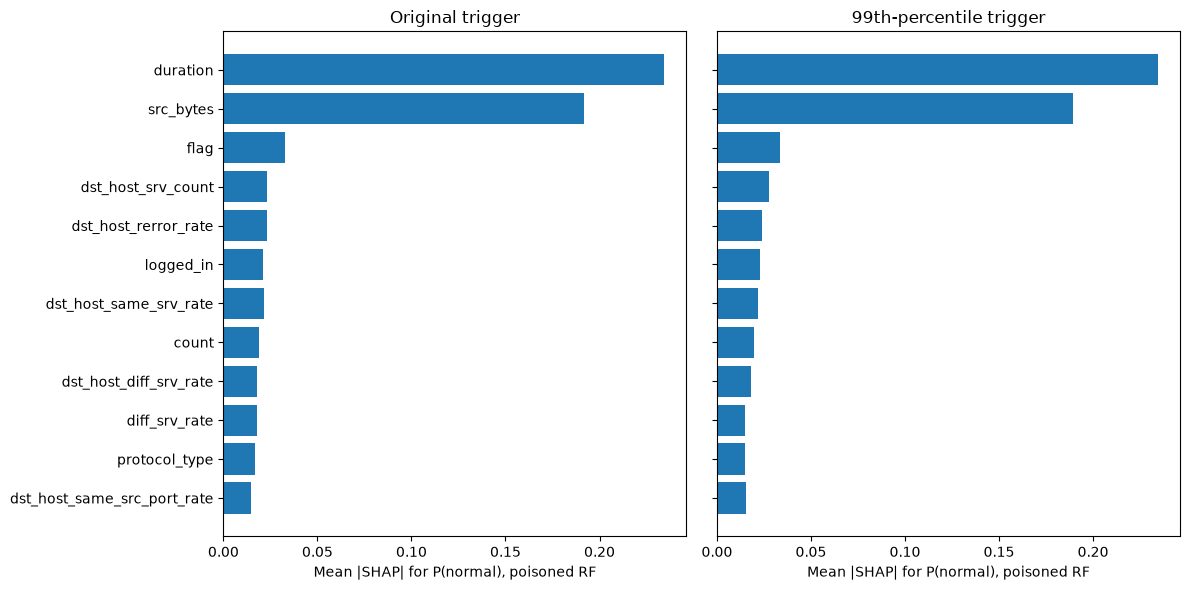

RF trigger features in the variant:
           RF clean, variant  RF poisoned, variant
duration            0.045742              0.234507
src_bytes           0.063652              0.189303


In [7]:
with np.load(os.path.join(ART_DIR, "poisoned_data_variant.npz"), allow_pickle=False) as data:
    X_trigger_variant = data["X_test_attacks_poisoned"]
    variant_trigger_features = data["trigger_feature_indices"]
    assert np.array_equal(attack_indices, data["test_attack_indices"])
    assert np.array_equal(trigger_features, variant_trigger_features)
with np.load(os.path.join(ART_DIR, "defense_results_variant.npz"), allow_pickle=False) as data:
    assert np.array_equal(attack_indices, data["test_attack_indices"])
    variant_feature_flags = data["feature_trigger_flags"]
    variant_feature_scores = data["feature_trigger_scores"]
    variant_before_predictions = data["dnn_test_predictions"][attack_indices]
    variant_after_predictions = data["dnn_trigger_predictions"]
variant_threshold = detector_bundle["variant_detectors"]["features"]["threshold"]
variant_rf = joblib.load(os.path.join(MODEL_DIR, "poisoned", "poisoned_rf_variant.joblib"))
assert np.array_equal(variant_rf.classes_, clean_rf.classes_)
variant_dnn = DNN(X_test.shape[1]).to(device)
variant_dnn.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "poisoned", "poisoned_dnn_variant.pth"),
    map_location=device, weights_only=True
))
variant_dnn.eval()
variant_rf_explainer = shap.TreeExplainer(
    variant_rf, feature_perturbation="tree_path_dependent", model_output="raw"
)
variant_summary_samples = X_trigger_variant[summary_indices]
variant_importance = pd.DataFrame({
    "RF clean, variant": np.abs(rf_normal_shap(rf_explainers["RF clean"], variant_summary_samples)).mean(axis=0),
    "RF poisoned, variant": np.abs(rf_normal_shap(variant_rf_explainer, variant_summary_samples)).mean(axis=0),
}, index=feature_names)
rf_trigger_comparison = pd.DataFrame({
    "Original trigger": importance["RF poisoned"],
    "99th-percentile trigger": variant_importance["RF poisoned, variant"],
})
variant_top_features = rf_trigger_comparison.mean(axis=1).nlargest(12).index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
for axis, name in zip(axes, rf_trigger_comparison):
    axis.barh(variant_top_features, rf_trigger_comparison.loc[variant_top_features, name])
    axis.set_title(name)
    axis.set_xlabel("Mean |SHAP| for P(normal), poisoned RF")
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "shap_rf_trigger_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()
print("RF trigger features in the variant:")
print(variant_importance.loc[[feature_names[i] for i in trigger_features]].to_string())

In [8]:
variant_rng = np.random.default_rng(SEED)
variant_eligible = (variant_before_predictions == 1) & (variant_after_predictions == 0)
variant_selected, variant_groups = [], []
for group, mask in [("detected", variant_eligible & variant_feature_flags),
                    ("missed", variant_eligible & ~variant_feature_flags)]:
    candidates = np.flatnonzero(mask)
    count = min(2, len(candidates))
    chosen = variant_rng.choice(candidates, size=count, replace=False)
    variant_selected.extend(chosen.tolist())
    variant_groups.extend([group] * count)
    print(f"Variant, {group}: {len(candidates)} available, {count} selected")
if not variant_selected:
    raise ValueError("No cases to explain: check the variant attack and defense results.")
variant_selected = np.array(variant_selected, dtype=int)
variant_count = len(variant_selected)
common_originals = X_test[attack_indices[variant_selected]]
variant_pairs = np.vstack([common_originals, X_trigger_variant[variant_selected]])
matched_max_pairs = np.vstack([common_originals, X_trigger[variant_selected]])

variant_values, variant_bases, variant_probabilities = {}, {}, {}
for name, rf, explainer, samples in [
    ("RF clean, variant", clean_rf, rf_explainers["RF clean"], variant_pairs),
    ("RF poisoned, max", poisoned_rf, rf_explainers["RF poisoned"], matched_max_pairs),
    ("RF poisoned, variant", variant_rf, variant_rf_explainer, variant_pairs),
]:
    variant_values[name] = rf_normal_shap(explainer, samples)
    variant_bases[name] = float(explainer.expected_value[normal_class])
    variant_probabilities[name] = rf.predict_proba(samples)[:, normal_class]
for name, dnn, samples in [
    ("DNN clean, variant", clean_dnn, variant_pairs),
    ("DNN poisoned, max", poisoned_dnn, matched_max_pairs),
    ("DNN poisoned, variant", variant_dnn, variant_pairs),
]:
    print(f"KernelSHAP: {name}", flush=True)
    np.random.seed(SEED)
    explainer = shap.KernelExplainer(
        lambda X, current_model=dnn: normal_probability(current_model, X), background, link="identity"
    )
    variant_values[name] = np.asarray(explainer.shap_values(samples, nsamples=512, l1_reg=0.0))
    variant_bases[name] = float(explainer.expected_value)
    variant_probabilities[name] = normal_probability(dnn, samples)
for name in variant_values:
    error = np.max(np.abs(variant_bases[name] + variant_values[name].sum(axis=1) - variant_probabilities[name]))
    print(f"{name}: reconstruction error = {error:.6f}")
    assert error < 0.001, "SHAP contributions are inconsistent with the explained probability."

variant_rows = []
for name in variant_values:
    original_trigger_case = name.endswith(", max")
    scores = feature_scores if original_trigger_case else variant_feature_scores
    threshold = feature_threshold if original_trigger_case else variant_threshold
    flags = feature_flags if original_trigger_case else variant_feature_flags
    for i, (position, group) in enumerate(zip(variant_selected, variant_groups)):
        variant_rows.append({
            "model_case": name, "test_index": int(attack_indices[position]),
            "selection_group_variant": group,
            "p_normal_before": variant_probabilities[name][i],
            "p_normal_after": variant_probabilities[name][i + variant_count],
            "trigger_shap_before": variant_values[name][i, trigger_features].sum(),
            "trigger_shap_after": variant_values[name][i + variant_count, trigger_features].sum(),
            "detector_score_after": scores[position], "detector_threshold": threshold,
            "detected_after": bool(flags[position]),
        })
variant_case_results = pd.DataFrame(variant_rows)
print(variant_case_results.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

Variant, detected: 7585 available, 2 selected
Variant, missed: 510 available, 2 selected
KernelSHAP: DNN clean, variant


100%|██████████| 8/8 [00:00<00:00, 78.63it/s]

KernelSHAP: DNN poisoned, max



100%|██████████| 8/8 [00:00<00:00, 81.53it/s]

KernelSHAP: DNN poisoned, variant



100%|██████████| 8/8 [00:00<00:00, 83.81it/s]


RF clean, variant: reconstruction error = 0.000000
RF poisoned, max: reconstruction error = 0.000000
RF poisoned, variant: reconstruction error = 0.000000
DNN clean, variant: reconstruction error = 0.000000
DNN poisoned, max: reconstruction error = 0.000000
DNN poisoned, variant: reconstruction error = 0.000000
           model_case  test_index selection_group_variant  p_normal_before  p_normal_after  trigger_shap_before  trigger_shap_after  detector_score_after  detector_threshold  detected_after
    RF clean, variant       17605                detected           0.0000          0.0600               0.0065             -0.0118                0.5683              0.5289            True
    RF clean, variant        9305                detected           0.0000          0.2000               0.0015              0.1077                0.6547              0.5289            True
    RF clean, variant        2714                  missed           0.0500          0.1200              -0.0218      

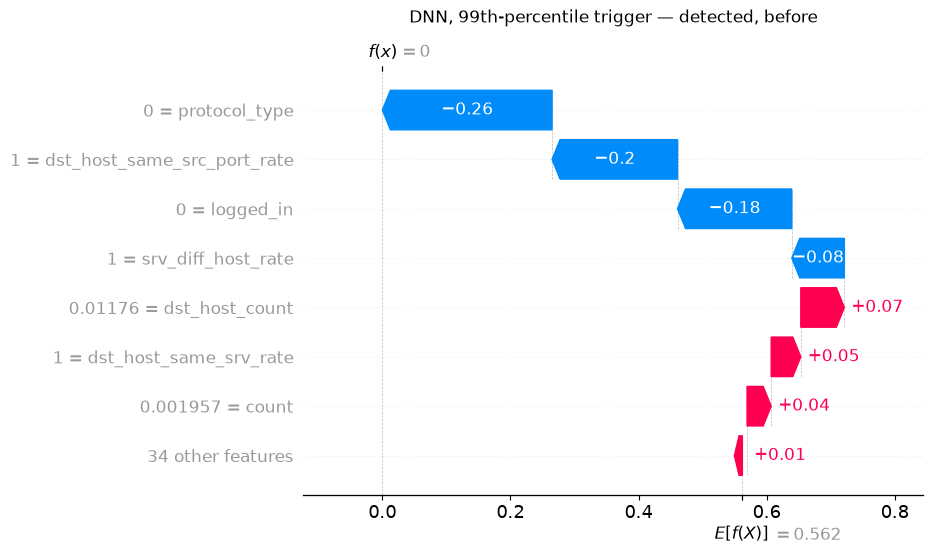

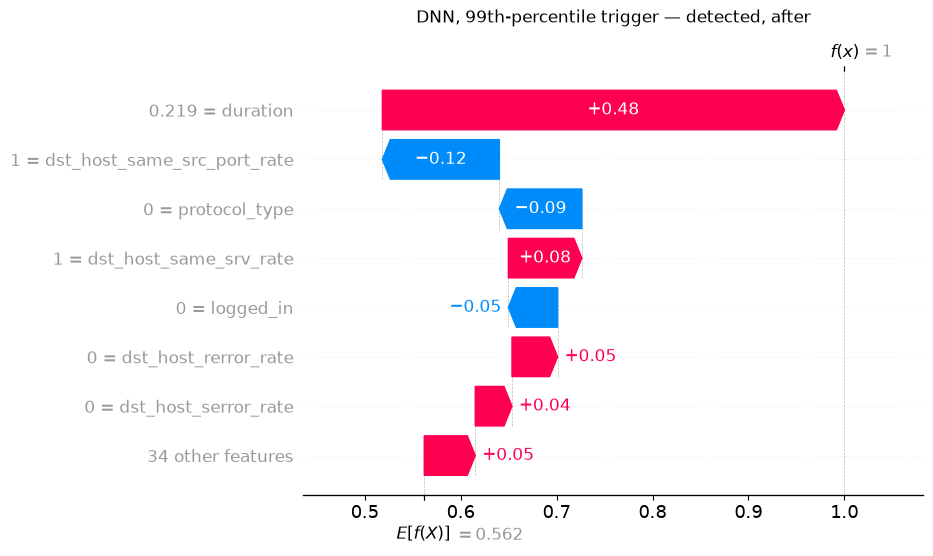

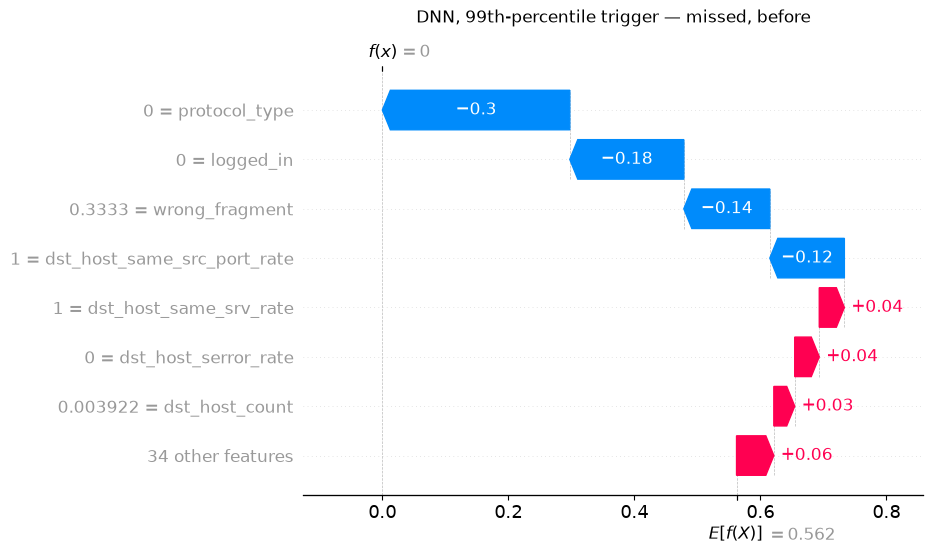

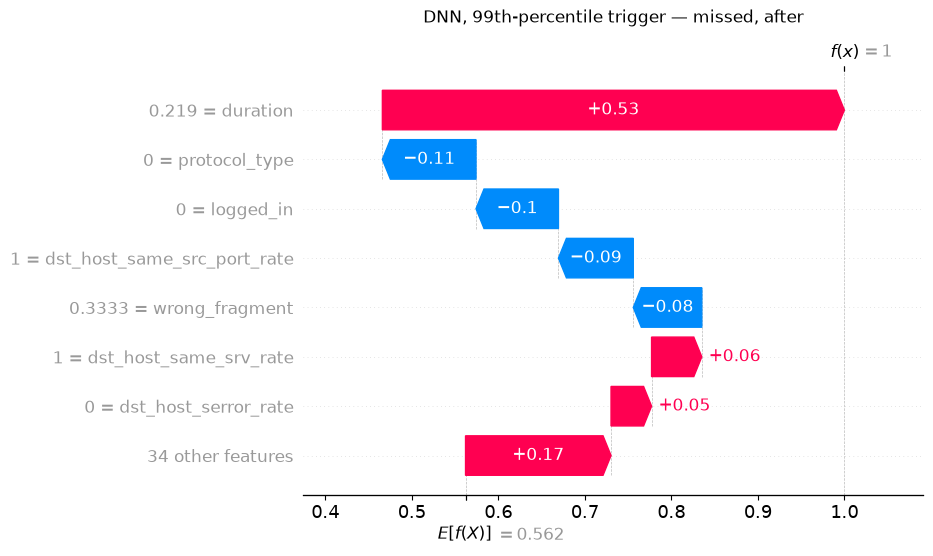

In [9]:
for group in dict.fromkeys(variant_groups):
    i = variant_groups.index(group)
    for offset, state in [(0, "before"), (variant_count, "after")]:
        row = i + offset
        explanation = shap.Explanation(
            values=variant_values["DNN poisoned, variant"][row],
            base_values=variant_bases["DNN poisoned, variant"],
            data=variant_pairs[row], feature_names=feature_names,
        )
        plt.figure()
        shap.plots.waterfall(explanation, max_display=8, show=False)
        order = np.argsort(-np.abs(explanation.values))[:7]
        labels = [f"{explanation.data[j]:.4g} = {feature_names[j]}" for j in order]
        axis = plt.gcf().axes[0]
        axis.set_yticks(range(8))
        axis.set_yticklabels(["34 other features"] + labels[::-1], fontsize=12)
        plt.gca().set_title(f"DNN, 99th-percentile trigger — {group}, {state}", pad=35)
        plt.savefig(os.path.join(PLOT_DIR, f"shap_dnn_variant_{group}_{state}.png"), dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()

In [10]:
variant_importance.to_csv(os.path.join(RESULT_DIR, "shap_rf_importance_variant.csv"), index_label="feature")
rf_trigger_comparison.to_csv(os.path.join(RESULT_DIR, "shap_rf_trigger_comparison.csv"), index_label="feature")
variant_case_results.to_csv(os.path.join(RESULT_DIR, "shap_trigger_case_comparison.csv"), index=False)
np.savez(
    os.path.join(ART_DIR, "shap_results_variant.npz"),
    background_train_indices=background_indices, summary_attack_positions=summary_indices,
    selected_attack_positions=variant_selected,
    selected_test_indices=attack_indices[variant_selected], selected_groups=np.asarray(variant_groups),
    feature_names=np.asarray(feature_names),
    paired_samples_variant=variant_pairs, paired_samples_max=matched_max_pairs,
    model_cases=np.asarray(list(variant_values)),
    values=np.stack([variant_values[name] for name in variant_values]),
    base_values=np.asarray([variant_bases[name] for name in variant_values]),
    probabilities=np.stack([variant_probabilities[name] for name in variant_values]),
)
print("Variant comparison and explanations saved in separate files\nOriginal analysis preserved")

Variant comparison and explanations saved in separate files
Original analysis preserved
